# Advanced Biometric Systems and Security (AI461)
## Assignment 1: User Authentication using Biometric Features
**Dataset:** 100 users, 10 samples each (5 enrollment, 5 test), 144 features per sample.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import euclidean, cosine

# Load biometric feature dataset
file_path = 'biomet_data.csv' if os.path.exists('biomet_data.csv') else '/content/biomet_data.csv'
data = pd.read_csv(file_path, header=None).values
print(f"Dataset shape: {data.shape}")

Dataset shape: (144, 1000)


In [2]:
num_users = 100
samples_per_user = 10
features_dim = 144

# Reshape data to (100 users, 10 samples, 144 features)
reshaped = np.zeros((num_users, samples_per_user, features_dim))
for u in range(num_users):
    reshaped[u] = data[:, u * samples_per_user : (u + 1) * samples_per_user].T

# Split into enrollment (first 5) and test (remaining 5)
train_data = reshaped[:, :5, :]
test_data = reshaped[:, 5:, :]

# Compute enrollment template (mean vector) for each user
train_templates = np.mean(train_data, axis=1)

print(f"Train data shape: {train_data.shape}")
print(f"Test data shape: {test_data.shape}")
print(f"Enrollment templates shape: {train_templates.shape}")

Train data shape: (100, 5, 144)
Test data shape: (100, 5, 144)
Enrollment templates shape: (100, 144)


In [3]:
# Compute genuine and imposter matching scores
genuine_euc, imposter_euc = [], []
genuine_cos, imposter_cos = [], []

for u_test in range(num_users):
    for s in range(5):
        test_vec = test_data[u_test, s, :]
        for u_train in range(num_users):
            tmpl_vec = train_templates[u_train, :]
            d_euc = euclidean(test_vec, tmpl_vec)
            s_cos = 1.0 - cosine(test_vec, tmpl_vec)
            if u_test == u_train:
                genuine_euc.append(d_euc)
                genuine_cos.append(s_cos)
            else:
                imposter_euc.append(d_euc)
                imposter_cos.append(s_cos)

genuine_euc, imposter_euc = np.array(genuine_euc), np.array(imposter_euc)
genuine_cos, imposter_cos = np.array(genuine_cos), np.array(imposter_cos)

print(f"Genuine comparisons: {len(genuine_euc)}")
print(f"Imposter comparisons: {len(imposter_euc)}")

Genuine comparisons: 500
Imposter comparisons: 49500


In [4]:
# Function to calculate FAR, FRR, EER, and Decidability Index
def compute_metrics(genuine, imposter, is_similarity=False, n_thresholds=1000):
    mu_gen, mu_imp = np.mean(genuine), np.mean(imposter)
    var_gen, var_imp = np.var(genuine), np.var(imposter)
    d_prime = np.abs(mu_gen - mu_imp) / np.sqrt(0.5 * (var_gen + var_imp))
    
    t_min = min(np.min(genuine), np.min(imposter))
    t_max = max(np.max(genuine), np.max(imposter))
    thresholds = np.linspace(t_min, t_max, n_thresholds)
    
    far_list, frr_list = [], []
    n_gen, n_imp = len(genuine), len(imposter)
    
    for t in thresholds:
        if is_similarity:
            far = np.sum(imposter >= t) / n_imp
            frr = np.sum(genuine < t) / n_gen
        else:
            far = np.sum(imposter <= t) / n_imp
            frr = np.sum(genuine > t) / n_gen
        far_list.append(far)
        frr_list.append(frr)
        
    far, frr = np.array(far_list), np.array(frr_list)
    
    diff = far - frr
    crossings = np.where(np.diff(np.sign(diff)))[0]
    if len(crossings) == 0:
        idx = np.argmin(np.abs(diff))
        eer = (far[idx] + frr[idx]) / 2.0
        eer_t = thresholds[idx]
    else:
        idx = crossings[0]
        t1, t2 = thresholds[idx], thresholds[idx + 1]
        far1, far2 = far[idx], far[idx + 1]
        frr1, frr2 = frr[idx], frr[idx + 1]
        denom = (far2 - far1) - (frr2 - frr1)
        eer_t = t1 + (frr1 - far1) * (t2 - t1) / denom if abs(denom) > 1e-9 else (t1 + t2) / 2.0
        eer = far1 + (eer_t - t1) * (far2 - far1) / (t2 - t1)
        
    return thresholds, far, frr, eer, eer_t, d_prime, mu_gen, var_gen, mu_imp, var_imp

thresh_euc, far_euc, frr_euc, eer_euc, eer_t_euc, d_euc, mu_gen_euc, var_gen_euc, mu_imp_euc, var_imp_euc = compute_metrics(
    genuine_euc, imposter_euc, is_similarity=False
)

thresh_cos, far_cos, frr_cos, eer_cos, eer_t_cos, d_cos, mu_gen_cos, var_gen_cos, mu_imp_cos, var_imp_cos = compute_metrics(
    genuine_cos, imposter_cos, is_similarity=True
)

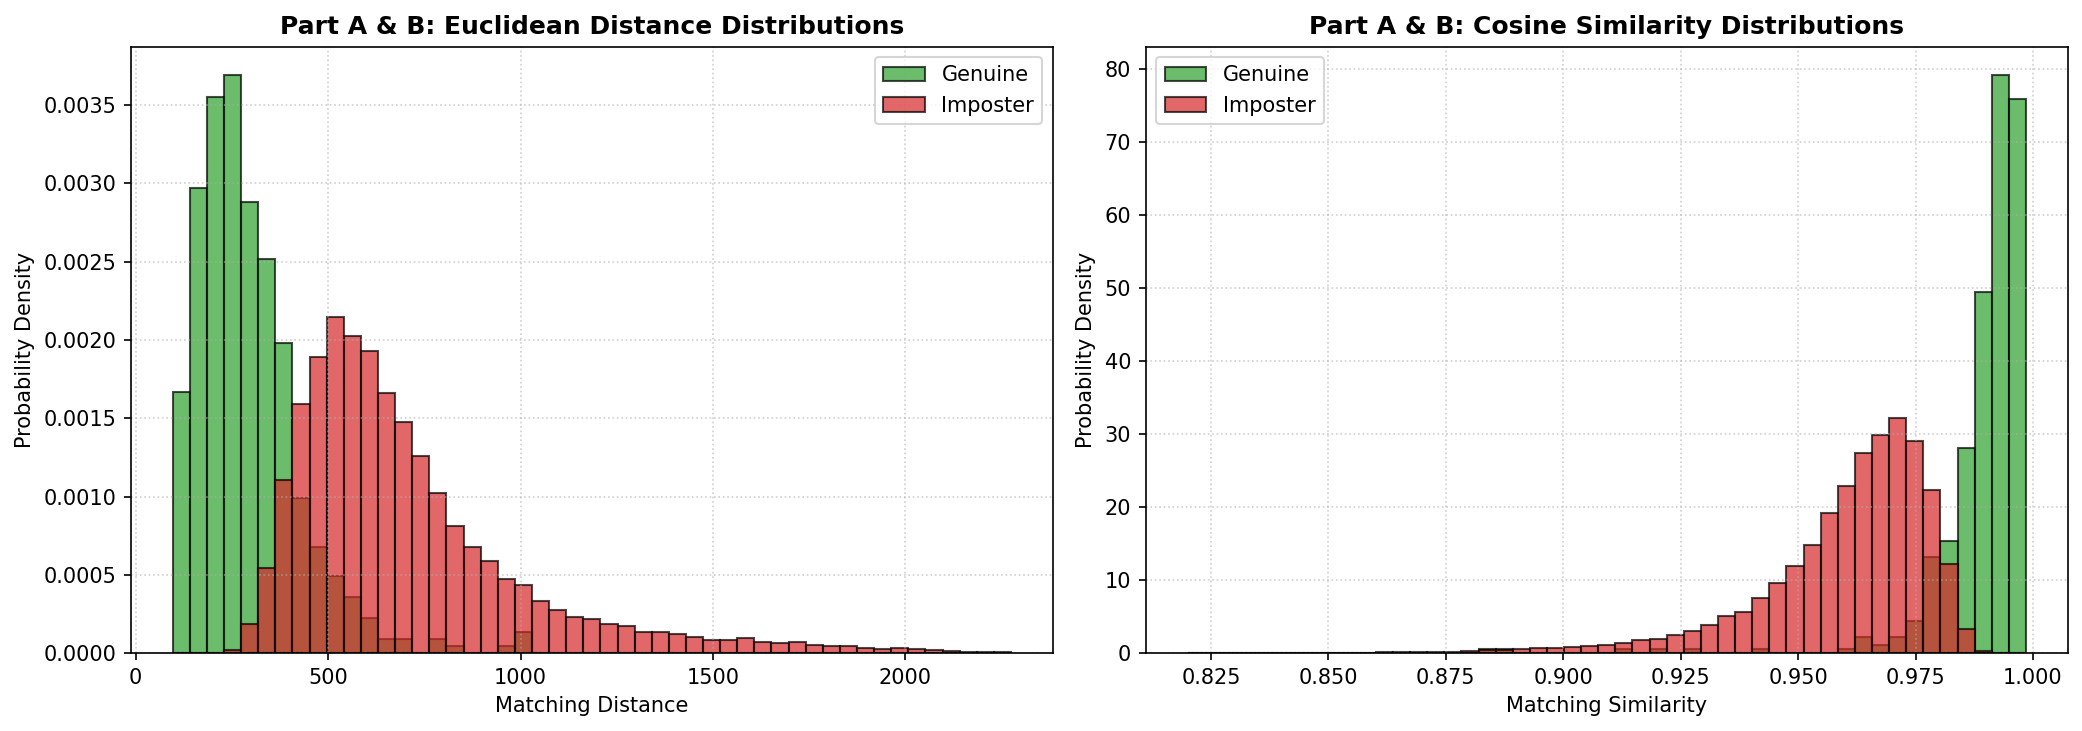

In [5]:
# Part A & B: Genuine and Imposter Score Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

euc_bins = np.linspace(min(genuine_euc.min(), imposter_euc.min()), max(genuine_euc.max(), imposter_euc.max()), 50)
axes[0].hist(genuine_euc, bins=euc_bins, alpha=0.7, label='Genuine', color='#2ca02c', edgecolor='black', density=True)
axes[0].hist(imposter_euc, bins=euc_bins, alpha=0.7, label='Imposter', color='#d62728', edgecolor='black', density=True)
axes[0].set_title('Part A & B: Euclidean Distance Distributions', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Matching Distance')
axes[0].set_ylabel('Probability Density')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

cos_bins = np.linspace(min(genuine_cos.min(), imposter_cos.min()), max(genuine_cos.max(), imposter_cos.max()), 50)
axes[1].hist(genuine_cos, bins=cos_bins, alpha=0.7, label='Genuine', color='#2ca02c', edgecolor='black', density=True)
axes[1].hist(imposter_cos, bins=cos_bins, alpha=0.7, label='Imposter', color='#d62728', edgecolor='black', density=True)
axes[1].set_title('Part A & B: Cosine Similarity Distributions', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Matching Similarity')
axes[1].set_ylabel('Probability Density')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

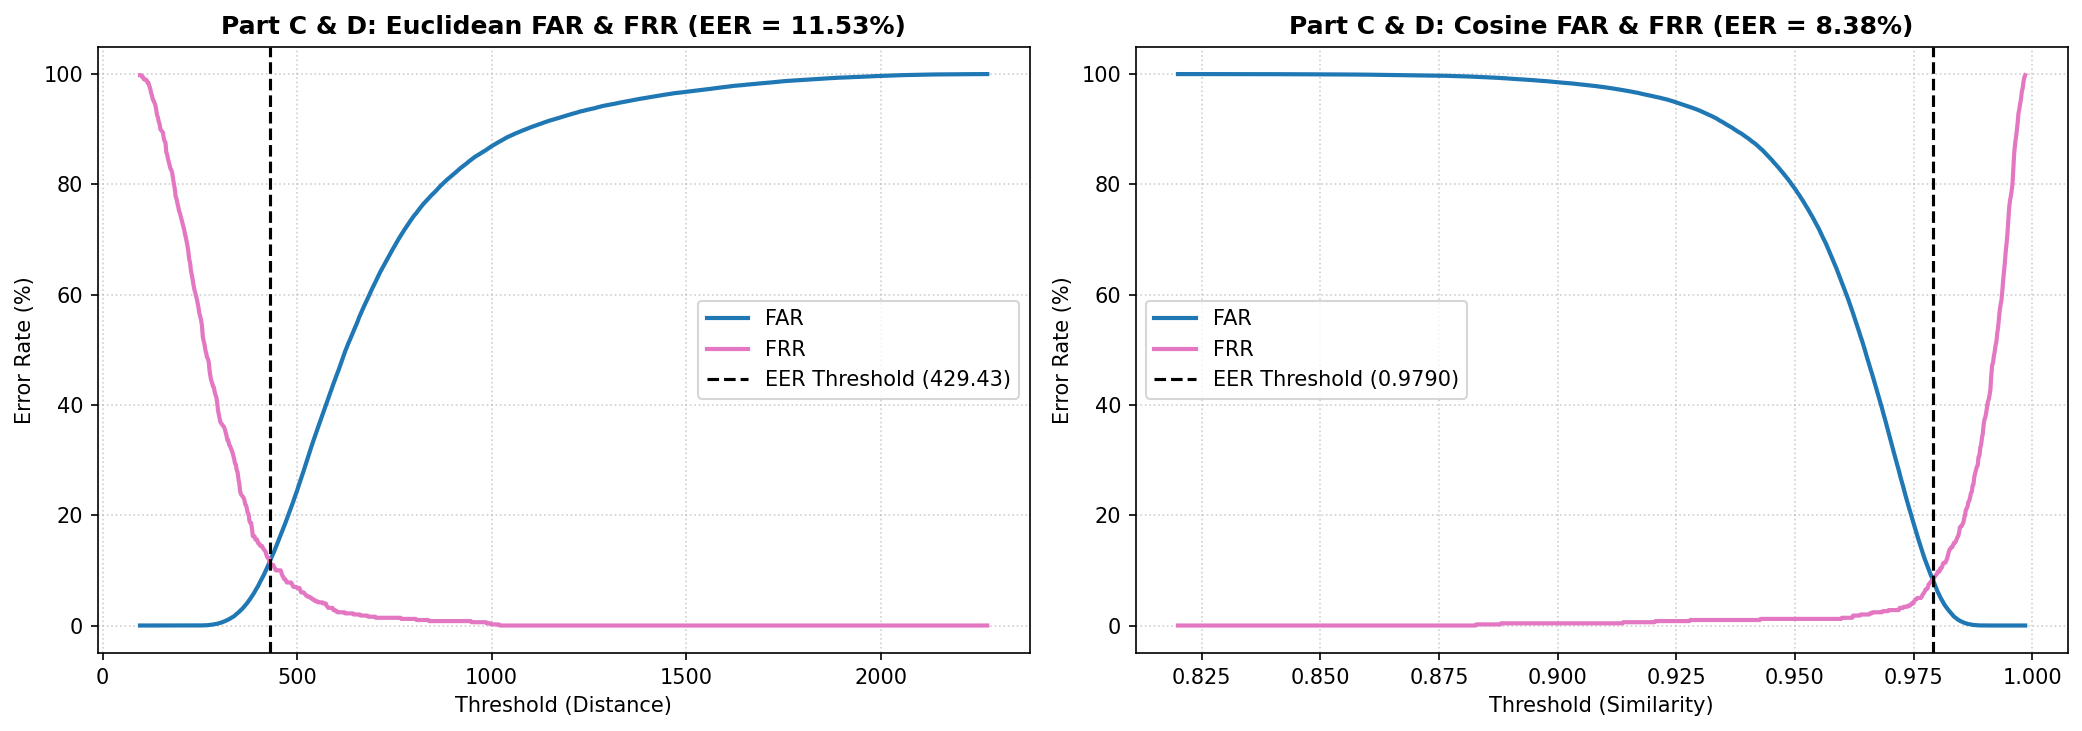

In [6]:
# Part C & D: FAR and FRR Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(thresh_euc, far_euc * 100, label='FAR', color='#1f77b4', lw=2)
axes[0].plot(thresh_euc, frr_euc * 100, label='FRR', color='#e377c2', lw=2)
axes[0].axvline(eer_t_euc, color='black', linestyle='--', lw=1.5, label=f'EER Threshold ({eer_t_euc:.2f})')
axes[0].set_title(f'Part C & D: Euclidean FAR & FRR (EER = {eer_euc*100:.2f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Threshold (Distance)')
axes[0].set_ylabel('Error Rate (%)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(thresh_cos, far_cos * 100, label='FAR', color='#1f77b4', lw=2)
axes[1].plot(thresh_cos, frr_cos * 100, label='FRR', color='#e377c2', lw=2)
axes[1].axvline(eer_t_cos, color='black', linestyle='--', lw=1.5, label=f'EER Threshold ({eer_t_cos:.4f})')
axes[1].set_title(f'Part C & D: Cosine FAR & FRR (EER = {eer_cos*100:.2f}%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Threshold (Similarity)')
axes[1].set_ylabel('Error Rate (%)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

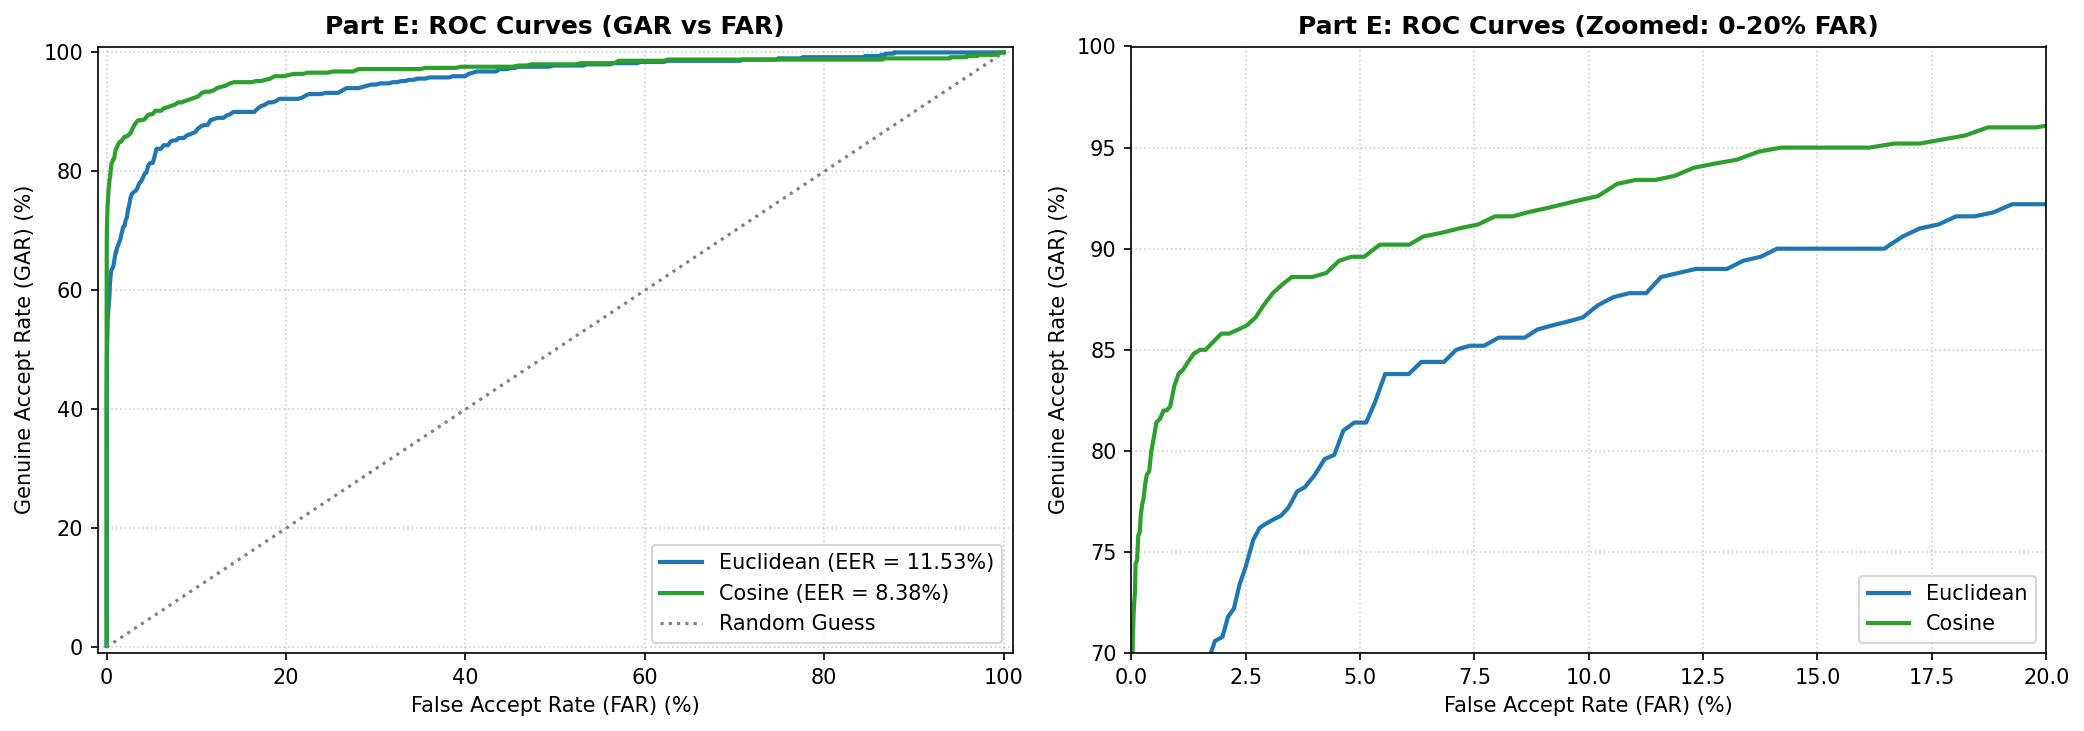

In [7]:
# Part E: Receiver Operating Characteristics (ROC) Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gar_euc = 1.0 - frr_euc
gar_cos = 1.0 - frr_cos

# Full ROC (0-100%)
axes[0].plot(far_euc * 100, gar_euc * 100, color='#1f77b4', lw=2, label=f'Euclidean (EER = {eer_euc*100:.2f}%)')
axes[0].plot(far_cos * 100, gar_cos * 100, color='#2ca02c', lw=2, label=f'Cosine (EER = {eer_cos*100:.2f}%)')
axes[0].plot([0, 100], [0, 100], color='gray', linestyle=':', label='Random Guess')
axes[0].set_xlim([-1, 101])
axes[0].set_ylim([-1, 101])
axes[0].set_xlabel('False Accept Rate (FAR) (%)')
axes[0].set_ylabel('Genuine Accept Rate (GAR) (%)')
axes[0].set_title('Part E: ROC Curves (GAR vs FAR)', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Zoomed ROC (0-20% FAR)
axes[1].plot(far_euc * 100, gar_euc * 100, color='#1f77b4', lw=2, label='Euclidean')
axes[1].plot(far_cos * 100, gar_cos * 100, color='#2ca02c', lw=2, label='Cosine')
axes[1].set_xlim([0, 20])
axes[1].set_ylim([70, 100])
axes[1].set_xlabel('False Accept Rate (FAR) (%)')
axes[1].set_ylabel('Genuine Accept Rate (GAR) (%)')
axes[1].set_title('Part E: ROC Curves (Zoomed: 0-20% FAR)', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [8]:
# Part F: Equal Error Rate (EER) and Decidability Index
results = pd.DataFrame({
    'Metric': [
        'Genuine Score Mean (mu_gen)',
        'Genuine Score Variance (var_gen)',
        'Imposter Score Mean (mu_imp)',
        'Imposter Score Variance (var_imp)',
        'Equal Error Rate (EER)',
        'EER Threshold',
        'Decidability Index (d\')'
    ],
    'Euclidean Distance': [
        f"{mu_gen_euc:.4f}",
        f"{var_gen_euc:.4f}",
        f"{mu_imp_euc:.4f}",
        f"{var_imp_euc:.4f}",
        f"{eer_euc * 100:.2f}%",
        f"{eer_t_euc:.4f}",
        f"{d_euc:.4f}"
    ],
    'Cosine Similarity': [
        f"{mu_gen_cos:.4f}",
        f"{var_gen_cos:.6f}",
        f"{mu_imp_cos:.4f}",
        f"{var_imp_cos:.6f}",
        f"{eer_cos * 100:.2f}%",
        f"{eer_t_cos:.4f}",
        f"{d_cos:.4f}"
    ]
})

sep = "=" * 60
print(sep)
print("Part F: Performance Summary & Comparison")
print(sep)
print(results.to_string(index=False))

Part F: Performance Summary & Comparison
                           Metric Euclidean Distance Cosine Similarity
      Genuine Score Mean (mu_gen)           291.6547            0.9895
 Genuine Score Variance (var_gen)         18350.1314          0.000120
     Imposter Score Mean (mu_imp)           703.8264            0.9604
Imposter Score Variance (var_imp)         91078.4397          0.000337
           Equal Error Rate (EER)             11.53%             8.38%
                    EER Threshold           429.4316            0.9790
          Decidability Index (d')             1.7621            1.9257


### Performance Analysis and Conclusion

**Which matching distance criteria performs the best?**

**Cosine Similarity performs significantly better than Euclidean Distance** based on the evaluation results:

1. **Lower Equal Error Rate (EER):**
   - Cosine Similarity achieves an EER of **8.38%**, compared to **11.53%** for Euclidean Distance (a **3.15% absolute error reduction**).

2. **Higher Decidability Index ($d'$):**
   - Cosine Similarity achieves a Decidability Index of **1.9257**, compared to **1.7621** for Euclidean Distance. A higher $d'$ value confirms greater statistical separation between genuine and imposter score distributions.

3. **Superior ROC Characteristics:**
   - The ROC curve for Cosine Similarity consistently dominates Euclidean Distance across all operating points, delivering a higher Genuine Accept Rate (GAR) for any acceptable False Accept Rate (FAR).

4. **Robustness to Scale Variations:**
   - In high-dimensional biometric vectors (144 features), Euclidean distance is sensitive to overall feature magnitude variations (such as lighting or sensor gain). Cosine similarity measures the angular orientation between feature vectors, effectively normalizing magnitude and yielding superior identity discrimination.